<a href="https://colab.research.google.com/github/widyy123/student-academic-risk-ml/blob/main/Untitled12.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

=== SAMPEL DATASET AKADEMIK MAHASISWA ===
   IPK_Early  Persentase_Hadir (%)  SKS_Lulus    Skor_TPA  \
0   3.599343             91.446943  45.943066  710.921194   
1   3.453173             98.316851  46.302304  631.221025   
2   3.407316             90.137081  44.725887  573.468790   
3   3.387542             87.948676  44.942742  613.679037   
4   3.793130             91.096895  44.202585  593.010073   

   Jam_Belajar_Mandiri        Status_Kelulusan  
0            14.297540  Tepat Waktu (Low Risk)  
1            16.627680  Tepat Waktu (Low Risk)  
2             9.825247  Tepat Waktu (Low Risk)  
3            10.763089  Tepat Waktu (Low Risk)  
4            13.366852  Tepat Waktu (Low Risk)  

Akurasi Model Machine Learning: 100.00%

=== CLASSIFICATION REPORT ===
                                precision    recall  f1-score   support

        Tepat Waktu (Low Risk)       1.00      1.00      1.00        40
       Waspada (Moderate Risk)       1.00      1.00      1.00        40
Berisiko

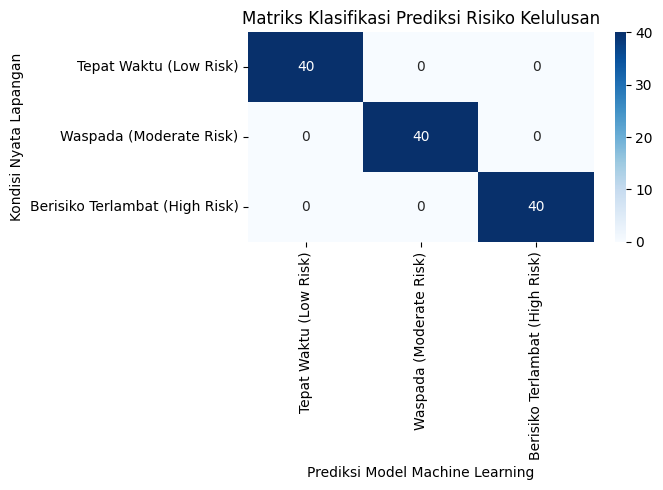

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# 1. SIMULASI DATASET AKADEMIK MAHASISWA

np.random.seed(42)
n_samples = 200

# Variabel Fitur:
# [IPK_Early, Persentase_Hadir, SKS_Lulus, Skor_TPA, Jam_Belajar]

# Kelas 0: Tepat Waktu (Low Risk)
low_risk = np.random.normal(loc=[3.5, 92, 44, 650, 15], scale=[0.2, 4, 3, 40, 3], size=(n_samples, 5))

# Kelas 1: Waspada (Moderate Risk)
mod_risk = np.random.normal(loc=[2.8, 78, 36, 520, 8], scale=[0.2, 5, 4, 50, 2], size=(n_samples, 5))

# Kelas 2: Berisiko Terlambat (High Risk)
high_risk = np.random.normal(loc=[2.1, 60, 24, 420, 3], scale=[0.3, 8, 5, 60, 1.5], size=(n_samples, 5))

X = np.vstack((low_risk, mod_risk, high_risk))
y = np.array([0]*n_samples + [1]*n_samples + [2]*n_samples)

class_names = ['Tepat Waktu (Low Risk)', 'Waspada (Moderate Risk)', 'Berisiko Terlambat (High Risk)']
feature_names = ['IPK_Early', 'Persentase_Hadir (%)', 'SKS_Lulus', 'Skor_TPA', 'Jam_Belajar_Mandiri']

df = pd.DataFrame(X, columns=feature_names)
df['Status_Kelulusan'] = [class_names[i] for i in y]

print("=== SAMPEL DATASET AKADEMIK MAHASISWA ===")
print(df.head())

# 2. PREPROCESSING & SPLIT DATASET (Training 80%, Testing 20%)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 3. TRAINING MODEL MACHINE LEARNING (SUPERVISED CLASSIFICATION)

mlp = MLPClassifier(hidden_layer_sizes=(32, 16), max_iter=300, random_state=42)
mlp.fit(X_train_scaled, y_train)

# 4. EVALUASI MODEL & REPORT

y_pred = mlp.predict(X_test_scaled)

print(f"\nAkurasi Model Machine Learning: {accuracy_score(y_test, y_pred) * 100:.2f}%\n")
print("=== CLASSIFICATION REPORT ===")
print(classification_report(y_test, y_pred, target_names=class_names))

# 5. VISUALISASI CONFUSION MATRIX

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.title('Matriks Klasifikasi Prediksi Risiko Kelulusan')
plt.xlabel('Prediksi Model Machine Learning')
plt.ylabel('Kondisi Nyata Lapangan')
plt.tight_layout()
plt.show()